In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


In [7]:
df=pd.read_csv("/Users/amankumar/Desktop/ML_LEARNING/Dataset/data.csv")
df.head()

,Employee_ID,Age,Experience,Education_Level,Job_Role,Monthly_Hours,Salary
0,EMP0001,59,30,Master,Data Scientist,208,158880
1,EMP0002,49,19,Master,Project Manager,186,113583
2,EMP0003,35,2,Bachelor,Software Engineer,188,60748
3,EMP0004,28,1,Bachelor,HR Specialist,172,23604
4,EMP0005,41,14,Master,Data Scientist,160,109709


In [6]:
df.shape

(500, 7)

In [7]:
df.columns

Index(['Employee_ID', 'Age', 'Experience', 'Education_Level', 'Job_Role',
       'Monthly_Hours', 'Salary'],
      dtype='str')

In [8]:
df.dtypes

Employee_ID          str
Age                int64
Experience         int64
Education_Level      str
Job_Role             str
Monthly_Hours      int64
Salary             int64
dtype: object

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Employee_ID      500 non-null    str  
 1   Age              500 non-null    int64
 2   Experience       500 non-null    int64
 3   Education_Level  500 non-null    str  
 4   Job_Role         500 non-null    str  
 5   Monthly_Hours    500 non-null    int64
 6   Salary           500 non-null    int64
dtypes: int64(4), str(3)
memory usage: 41.5 KB


In [9]:
df.isnull().sum()

Employee_ID        0
Age                0
Experience         0
Education_Level    0
Job_Role           0
Monthly_Hours      0
Salary             0
dtype: int64

In [10]:
df.describe()

,Age,Experience,Monthly_Hours,Salary
count,500.000000,500.000000,500.000000,500.000000
mean,41.436000,9.634000,176.904000,81964.130000
std,11.656142,8.953904,23.479296,32426.745555
min,21.000000,0.000000,140.000000,23604.000000
25%,32.000000,2.000000,156.750000,59027.500000
50%,43.000000,7.000000,174.000000,75159.000000
75%,52.000000,15.250000,197.000000,102909.750000
max,60.000000,35.000000,220.000000,185104.000000


In [11]:
role_count=df['Job_Role'].value_counts()
role_count

Job_Role
Software Engineer    93
HR Specialist        92
Project Manager      85
Data Analyst         83
Business Analyst     81
Data Scientist       66
Name: count, dtype: int64

In [12]:
df.groupby('Job_Role')['Salary'].mean().sort_values(ascending=False)

Job_Role
Data Scientist       97286.621212
Project Manager      90371.882353
Software Engineer    85084.193548
Business Analyst     79273.456790
Data Analyst         73320.373494
HR Specialist        70217.032609
Name: Salary, dtype: float64

In [13]:
X=df[['Age','Experience','Monthly_Hours']]
y=df['Salary']

In [14]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [15]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ -31.42,3284.91, 122.97]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['Age','Experience','Monthly_Hours']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.954e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [16]:
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Coefficients: [ -31.42159382 3284.90607236  122.9712157 ]
Intercept: 29540.503291632973


In [17]:
y_pred=model.predict(X_test)
print("Predicted Salaries:")
print(y_pred[:10])

Predicted Salaries:
[ 85956.95003943  72029.87590269  75127.78757362 156537.06820167
 152641.2012085   80991.19401797  49539.8140588   73281.68417664
  88471.07206229  90335.826413  ]


In [18]:
comparison=pd.DataFrame({
    "Actual_Salary": y_test.values,
    "Predicted_Salary": y_pred.round(2)
})
comparison.head(10)

,Actual_Salary,Predicted_Salary
0,99280,85956.95
1,87644,72029.88
2,80038,75127.79
3,152949,156537.07
4,156258,152641.20
5,72565,80991.19
6,54909,49539.81
7,78569,73281.68
8,97512,88471.07
9,85744,90335.83


In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print("MAE: ", mean_absolute_error(y_test,y_pred))
print("MSE: ", mean_squared_error(y_test,y_pred))
print("R2 Score: ",r2_score(y_test,y_pred))


MAE:  11286.799094691032
MSE:  203080778.08555183
R2 Score:  0.8090868456529263


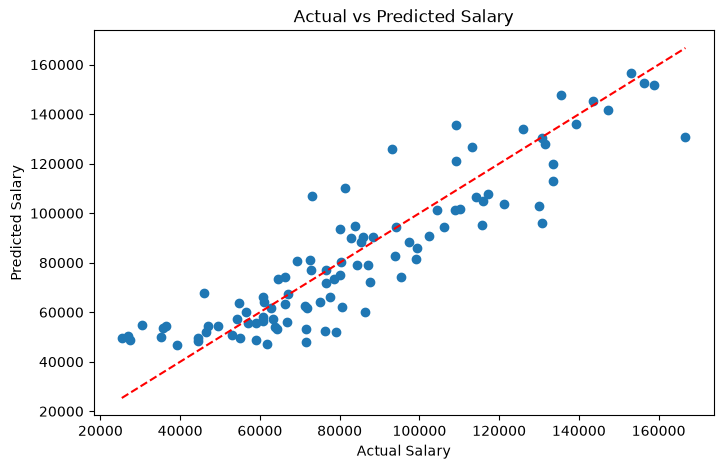

In [20]:
plt.figure(figsize=(8,5))
plt.scatter(y_test,y_pred,label="Predictions")
plt.plot(
    [y_test.min(),y_test.max()],
    [y_test.min(),y_test.max()],
    "r--",
    label="Perfect Prediction"
)
plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")
plt.show()

In [21]:
residuals = y_test - y_pred
residuals.head(10)

361    13323.049961
73     15614.124097
374     4910.212426
155    -3588.068202
104     3616.798792
394    -8426.194018
377     5369.185941
124     5287.315823
68      9040.927938
450    -4591.826413
Name: Salary, dtype: float64

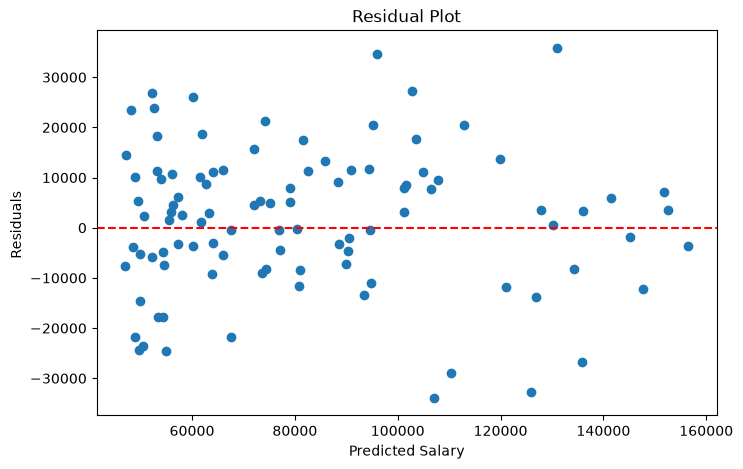

In [22]:
plt.figure(figsize=(8,5))
plt.scatter(y_pred,residuals)
plt.axhline(y=0,color="red",linestyle="--")

plt.xlabel("Predicted Salary")
plt.ylabel("Residuals ")
plt.title("Residual Plot")
plt.show()

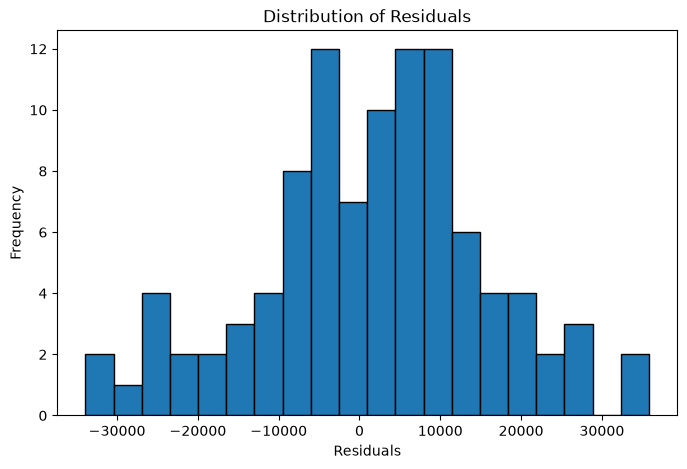

In [23]:
plt.figure(figsize=(8,5))
plt.hist(residuals,bins=20,edgecolor="black")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.show()

In [24]:
comparison["Residual"] = y_test.to_numpy() - y_pred

comparison["Absolute_Error"] = abs(comparison["Residual"])

comparison.head(10)

,Actual_Salary,Predicted_Salary,Residual,Absolute_Error
0,99280,85956.95,13323.049961,13323.049961
1,87644,72029.88,15614.124097,15614.124097
2,80038,75127.79,4910.212426,4910.212426
3,152949,156537.07,-3588.068202,3588.068202
4,156258,152641.20,3616.798792,3616.798792
5,72565,80991.19,-8426.194018,8426.194018
6,54909,49539.81,5369.185941,5369.185941
7,78569,73281.68,5287.315823,5287.315823
8,97512,88471.07,9040.927938,9040.927938
9,85744,90335.83,-4591.826413,4591.826413


In [25]:
comparison.sort_values(
    by="Absolute_Error",
    ascending=False
).head(10)

,Actual_Salary,Predicted_Salary,Residual,Absolute_Error
27,166726,130899.02,35826.977861,35826.977861
62,130638,95911.01,34726.991806,34726.991806
21,73107,107031.11,-33924.110483,33924.110483
47,93050,125872.78,-32822.782926,32822.782926
22,81449,110310.59,-28861.586236,28861.586236
52,130099,102871.83,27227.169897,27227.169897
17,78964,52147.02,26816.979135,26816.979135
39,109098,135761.64,-26663.637897,26663.637897
11,86239,60185.88,26053.122719,26053.122719
93,30537,55032.77,-24495.771695,24495.771695
